# Walmart Weekly Sales Forecasting: Store-Level Prediction with Extra Trees and Time-Based Validation

**Objective:** predict weekly sales per store (regression). The EDA comes first and decides how the data is prepared for modeling.

**Dataset:** `Walmart.csv`, 6,435 rows, 45 stores, weekly data from 2010-02-05 to 2012-10-26.

| Column | Description |
|---|---|
| `Store` | Store ID (a label, not a quantity) |
| `Date` | Week of the sales record |
| `Weekly_Sales` | Sales of the store in that week (target) |
| `Holiday_Flag` | 1 if the week contains a holiday, otherwise 0 |
| `Temperature` | Regional temperature (°F) |
| `Fuel_Price` | Regional fuel price |
| `CPI` | Consumer price index |
| `Unemployment` | Regional unemployment rate |

**Contents**
1. Project Overview and Setup
2. Data Loading and Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Train-Test Split
6. Baseline Models
7. Preprocessing Pipeline
8. Modeling
9. Cross-Validation
10. Hyperparameter Tuning
11. Final Evaluation
12. Model Interpretation
13. Conclusion and Recommendations

### 1.1. Data Source

- **Dataset:** *Walmart Dataset (Retail)* on Kaggle, file `Walmart.csv`: https://www.kaggle.com/datasets/rutuspatel/walmart-dataset-retail
- **Origin:** the data follows the structure of the Kaggle competition *Walmart Recruiting: Store Sales Forecasting*: https://www.kaggle.com/c/walmart-recruiting-store-sales-forecasting
- **Content:** weekly sales of 45 Walmart stores (6,435 rows, 2010-02-05 to 2012-10-26) with holiday flag, temperature, fuel price, CPI and unemployment rate.
- **Accessed:** October 2026.
- **Note:** the dataset has no information about store size, location or promotions, so differences between stores are described but not explained.

### 1.2. Tools

| Purpose | Tool |
|---|---|
| Language and environment | Python 3 in Jupyter Notebook (Anaconda) |
| Data handling | `pandas`, `numpy` |
| Visualization | `matplotlib`, `seaborn`, `plotly.express` |
| Preprocessing and pipeline | `scikit-learn`: `ColumnTransformer`, `OneHotEncoder`, `StandardScaler`, `Pipeline` |
| Models | `scikit-learn`: `DummyRegressor`, `Ridge`, `RandomForestRegressor`, `ExtraTreesRegressor`, `HistGradientBoostingRegressor` |
| Validation and tuning | `scikit-learn`: `TimeSeriesSplit`, `cross_validate`, `RandomizedSearchCV` |
| Evaluation and interpretation | `scikit-learn` metrics (MAE, RMSE, R²), WAPE (own formula), `permutation_importance`, `feature_importances_` |

### 1.3. Import Libraries

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import plotly.express as px
from sklearn.model_selection import train_test_split, cross_validate, TimeSeriesSplit, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance



sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format   # no scientific notation, thousands separator

# axis label formatter: 1,500,000 -> 1.5M
millions = FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M')

# 2. Data Loading and Cleaning

### 2.1. Inspect Data

In [2]:
df = pd.read_csv('Walmart.csv')

In [3]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,"1,643,690.90",0,42.31,2.57,211.10,8.11
1,1,12-02-2010,"1,641,957.44",1,38.51,2.55,211.24,8.11
2,1,19-02-2010,"1,611,968.17",0,39.93,2.51,211.29,8.11
3,1,26-02-2010,"1,409,727.59",0,46.63,2.56,211.32,8.11
4,1,05-03-2010,"1,554,806.68",0,46.50,2.62,211.35,8.11


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 465.2 KB


In [5]:
df.shape

(6435, 8)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,"6,435.00",23.00,12.99,1.00,12.00,23.00,34.00,45.00
Weekly_Sales,"6,435.00","1,046,964.88","564,366.62","209,986.25","553,350.10","960,746.04","1,420,158.66","3,818,686.45"
Holiday_Flag,"6,435.00",0.07,0.26,0.00,0.00,0.00,0.00,1.00
Temperature,"6,435.00",60.66,18.44,-2.06,47.46,62.67,74.94,100.14
Fuel_Price,"6,435.00",3.36,0.46,2.47,2.93,3.44,3.73,4.47
CPI,"6,435.00",171.58,39.36,126.06,131.74,182.62,212.74,227.23
Unemployment,"6,435.00",8.00,1.88,3.88,6.89,7.87,8.62,14.31


### 2.2. Data Cleaning

In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values per column:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Number of duplicate rows: 0


### 2.3. Data Types and Date Features

In [8]:
# Date was read as text (dd-mm-yyyy) -> convert to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
print("Unparseable dates:", df['Date'].isna().sum())   # should be 0

df['Store'] = df['Store'].astype('category')   # store ID, not a quantity
# Holiday_Flag stays 0/1 (numeric) so it can be used in the correlation analysis

# Date features (a model cannot use raw dates)
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())
print("Weeks per store:", df.groupby('Store', observed=True)['Date'].count().unique())

Unparseable dates: 0
Date range: 2010-02-05 to 2012-10-26
Weeks per store: [143]


# 3. Exploratory Data Analysis (EDA)

### 3.1. Target Distribution (`Weekly_Sales`)

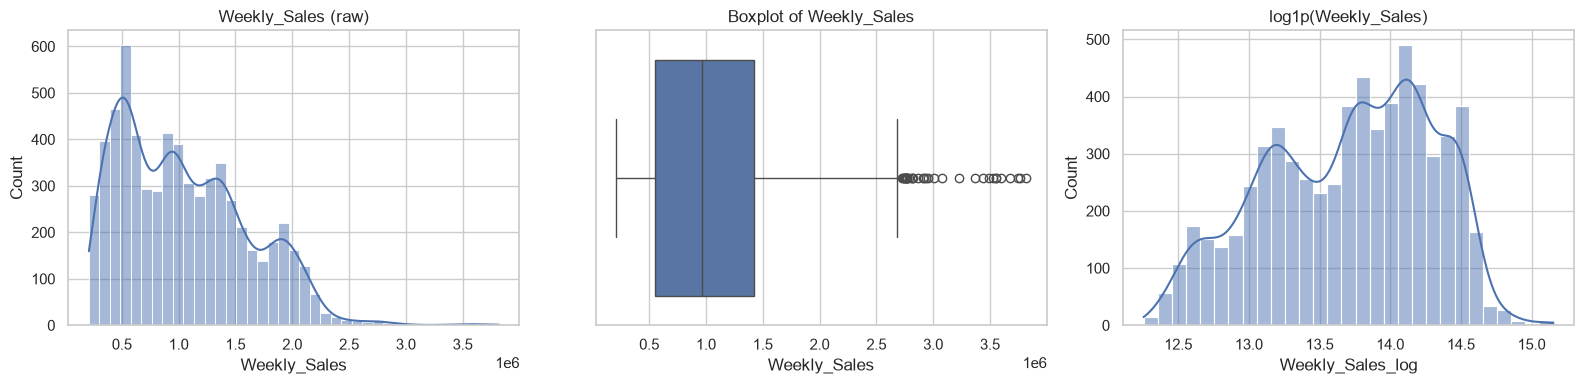

count       6,435.00
mean    1,046,964.88
std       564,366.62
min       209,986.25
25%       553,350.10
50%       960,746.04
75%     1,420,158.66
max     3,818,686.45
Name: Weekly_Sales, dtype: float64
Skewness (raw)  : 0.668
Skewness (log1p): -0.306


In [9]:
df['Weekly_Sales_log'] = np.log1p(df['Weekly_Sales'])   # log-transformed target (original column is kept)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['Weekly_Sales'], kde=True, ax=ax[0])
ax[0].set_title('Weekly_Sales (raw)')
sns.boxplot(x=df['Weekly_Sales'], ax=ax[1])
ax[1].set_title('Boxplot of Weekly_Sales')
sns.histplot(df['Weekly_Sales_log'], kde=True, ax=ax[2])
ax[2].set_title('log1p(Weekly_Sales)')
plt.tight_layout()
plt.show()

print(df['Weekly_Sales'].describe())
print('Skewness (raw)  :', round(df['Weekly_Sales'].skew(), 3))
print('Skewness (log1p):', round(df['Weekly_Sales_log'].skew(), 3))

*`Weekly_Sales` is moderately right-skewed (skewness = 0.668). After the `log1p` transformation the distribution is more symmetric (skewness = -0.306). The column `Weekly_Sales_log` was created for later use, while the original `Weekly_Sales` column is kept.*

### 3.2. Outlier Check on Numerical Features

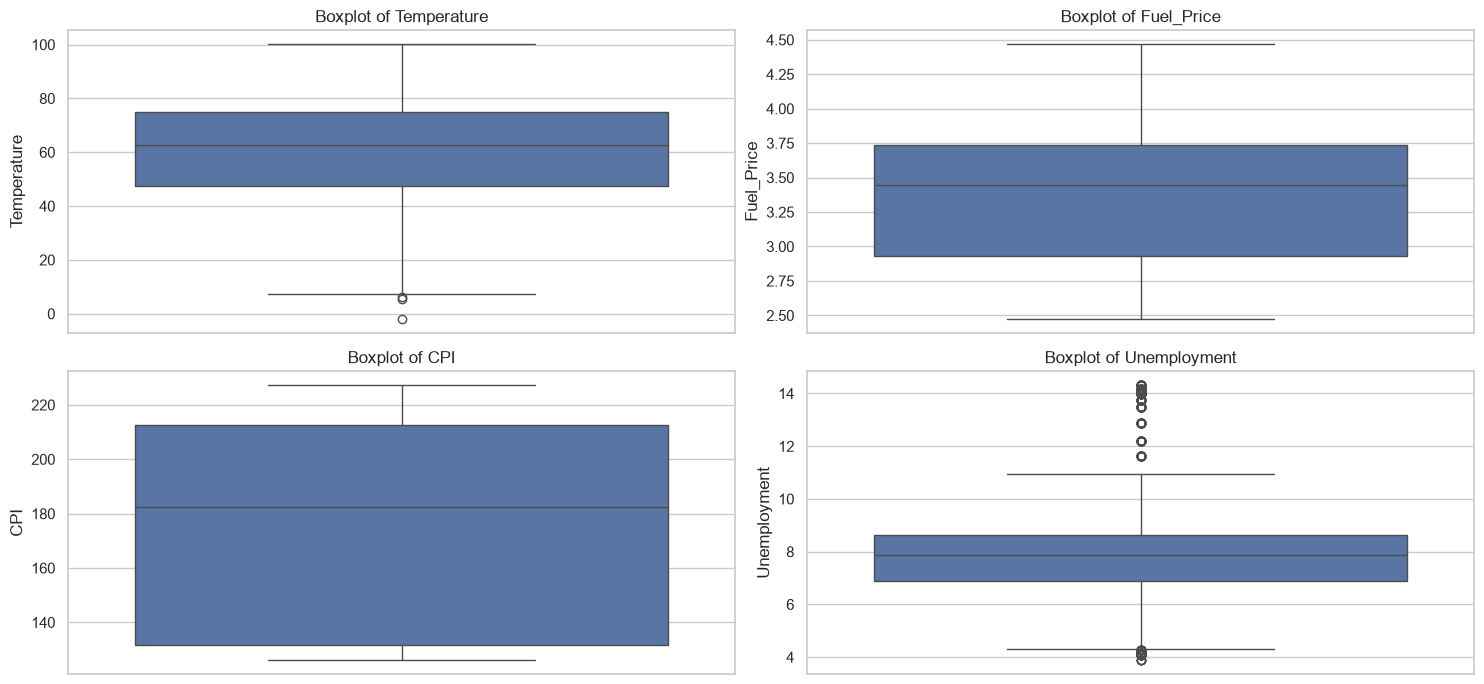

In [10]:
num_features = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for ax, c in zip(axes.flatten(), num_features):
    sns.boxplot(data=df, y=c, ax=ax)
    ax.set_title(f'Boxplot of {c}')
plt.tight_layout()
plt.show()

In [11]:
for col in num_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_out = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f'{col}: lower bound {lower_bound:.1f} | upper bound {upper_bound:.1f} | outliers: {n_out}')

Temperature: lower bound 6.2 | upper bound 116.2 | outliers: 3
Fuel_Price: lower bound 1.7 | upper bound 4.9 | outliers: 0
CPI: lower bound 10.2 | upper bound 334.3 | outliers: 0
Unemployment: lower bound 4.3 | upper bound 11.2 | outliers: 481


In [12]:
# Which stores do the Unemployment outliers come from?
q1, q3 = df['Unemployment'].quantile([0.25, 0.75])
iqr = q3 - q1
unemp_outliers = df[(df['Unemployment'] > q3 + 1.5 * iqr) | (df['Unemployment'] < q1 - 1.5 * iqr)]

print(unemp_outliers['Store'].astype(int).value_counts())
print('Stores affected:', unemp_outliers['Store'].nunique())

Store
12    126
28    126
38    126
23     43
40     43
4      17
Name: count, dtype: int64
Stores affected: 6


*The `Unemployment` outliers (481 rows, about 7.5% of the data) come from only 6 stores (12, 28, 38, 23, 40 and 4). Unemployment is regional, so these outliers reflect local economic conditions and not data errors. The `Temperature` outliers (3 rows) are extreme but physically plausible cold weeks. All outliers are kept.*

### 3.3. Store-Level Analysis

In [13]:
store_stats = df.groupby('Store', observed=True)['Weekly_Sales'].agg(['mean', 'std'])
store_stats['std_pct_of_mean'] = store_stats['std'] / store_stats['mean'] * 100
store_stats = store_stats.sort_values('mean', ascending=False)

print('Top 3 stores:')
print(store_stats.head(3).round(0))
print('\nBottom 3 stores:')
print(store_stats.tail(3).round(0))
print(f"\nHighest vs lowest store average: {store_stats['mean'].max() / store_stats['mean'].min():.1f}x")

Top 3 stores:
              mean        std  std_pct_of_mean
Store                                         
20    2,107,677.00 275,901.00            13.00
4     2,094,713.00 266,201.00            13.00
14    2,020,978.00 317,570.00            16.00

Bottom 3 stores:
            mean       std  std_pct_of_mean
Store                                      
5     318,012.00 37,738.00            12.00
44    302,749.00 24,763.00             8.00
33    259,862.00 24,133.00             9.00

Highest vs lowest store average: 8.1x


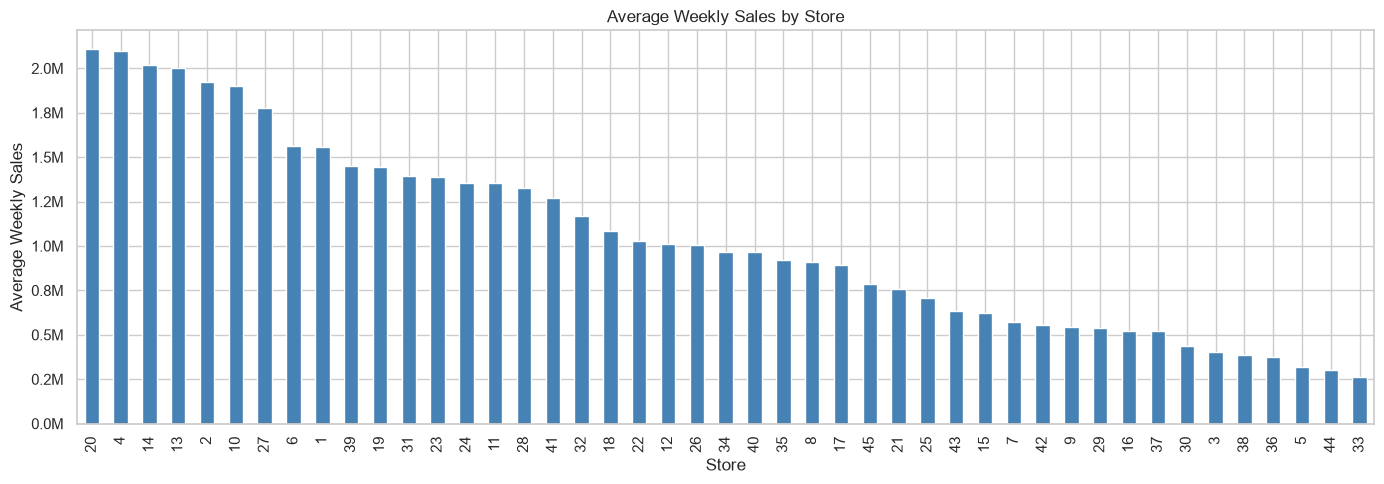

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
store_stats['mean'].plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Average Weekly Sales by Store')
ax.set_xlabel('Store')
ax.set_ylabel('Average Weekly Sales')
ax.yaxis.set_major_formatter(millions)
plt.tight_layout()
plt.show()

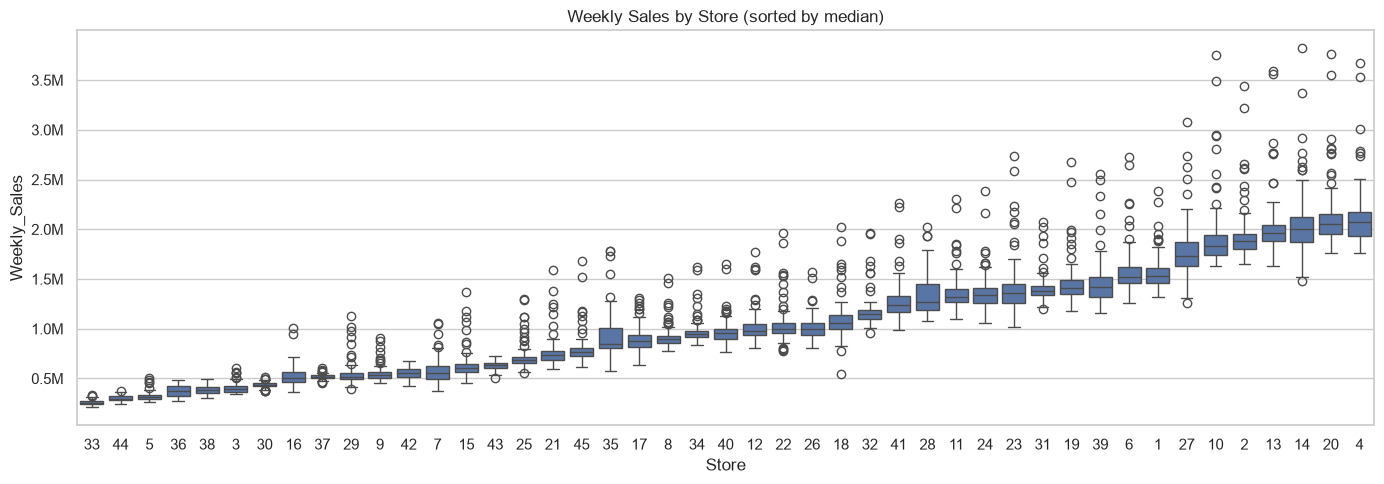

In [15]:
store_order = df.groupby('Store', observed=True)['Weekly_Sales'].median().sort_values().index

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=df, x='Store', y='Weekly_Sales', order=store_order, ax=ax)
ax.set_title('Weekly Sales by Store (sorted by median)')
ax.yaxis.set_major_formatter(millions)
plt.tight_layout()
plt.show()

### 3.4. Holiday Effect

In [16]:
normal = df.loc[df['Holiday_Flag'] == 0, 'Weekly_Sales']
holiday = df.loc[df['Holiday_Flag'] == 1, 'Weekly_Sales']

difference = holiday.mean() - normal.mean()
percentage = difference / normal.mean() * 100

print(f'Holiday weeks share of data : {len(holiday) / len(df):.1%}')
print(f'Normal weeks  (mean) : {normal.mean():,.0f}')
print(f'Holiday weeks (mean) : {holiday.mean():,.0f}')
print(f'Difference           : {difference:,.0f}')
print(f'Percentage           : {percentage:.2f}%')
print(f'Median normal vs holiday: {normal.median():,.0f} vs {holiday.median():,.0f}')

Holiday weeks share of data : 7.0%
Normal weeks  (mean) : 1,041,256
Holiday weeks (mean) : 1,122,888
Difference           : 81,632
Percentage           : 7.84%
Median normal vs holiday: 956,211 vs 1,018,538


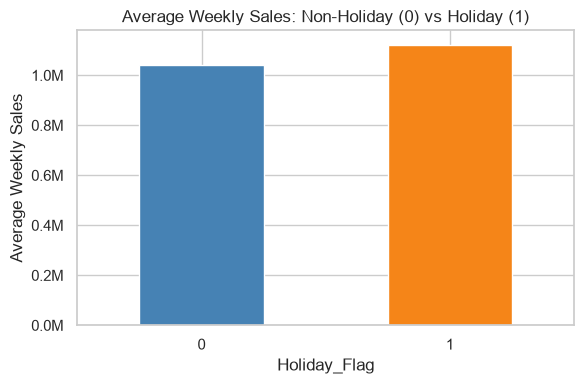

In [17]:
flag_sales = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()

fig, ax = plt.subplots(figsize=(6, 4))
flag_sales.plot(kind='bar', ax=ax, color=['steelblue', '#F58518'])
ax.set_title('Average Weekly Sales: Non-Holiday (0) vs Holiday (1)')
ax.set_xlabel('Holiday_Flag')
ax.set_ylabel('Average Weekly Sales')
ax.yaxis.set_major_formatter(millions)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Sales relative to each store's own average week (1.0 = average, 1.2 = 20% above average)
df['Sales_vs_Store_Avg'] = df['Weekly_Sales'] / df.groupby('Store', observed=True)['Weekly_Sales'].transform('mean')

Flagged weeks outside the four expected months: 0
Sales change vs store average, by holiday (%):
Holiday
Thanksgiving   37.60
Super Bowl      2.90
Labor Day       0.00
25 December    -7.90


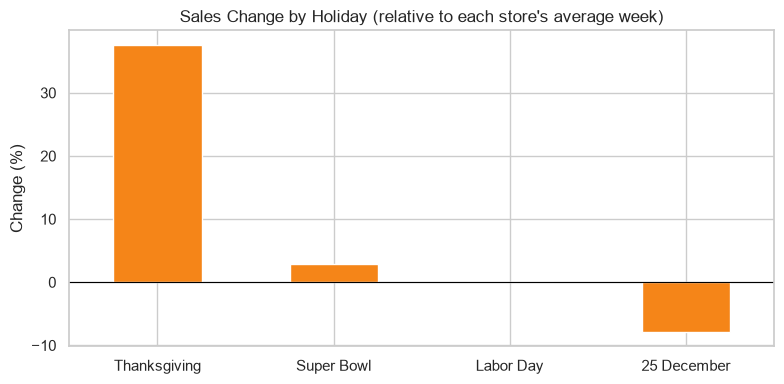

In [19]:
# Flagged weeks fall in Feb (Super Bowl), Sep (Labor Day), Nov (Thanksgiving), Dec (25 December)
holiday_names = {2: 'Super Bowl', 9: 'Labor Day', 11: 'Thanksgiving', 12: '25 December'}
hol = df[df['Holiday_Flag'] == 1].copy()
hol['Holiday'] = hol['Month'].map(holiday_names)
print('Flagged weeks outside the four expected months:', hol['Holiday'].isna().sum())   # should be 0

by_holiday = hol.groupby('Holiday')['Sales_vs_Store_Avg'].mean().sort_values(ascending=False)
by_holiday_pct = ((by_holiday - 1) * 100).round(1)
print('Sales change vs store average, by holiday (%):')
print(by_holiday_pct.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
by_holiday_pct.plot(kind='bar', ax=ax, color='#F58518')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title("Sales Change by Holiday (relative to each store's average week)")
ax.set_xlabel('')
ax.set_ylabel('Change (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.5. Trend and Seasonality

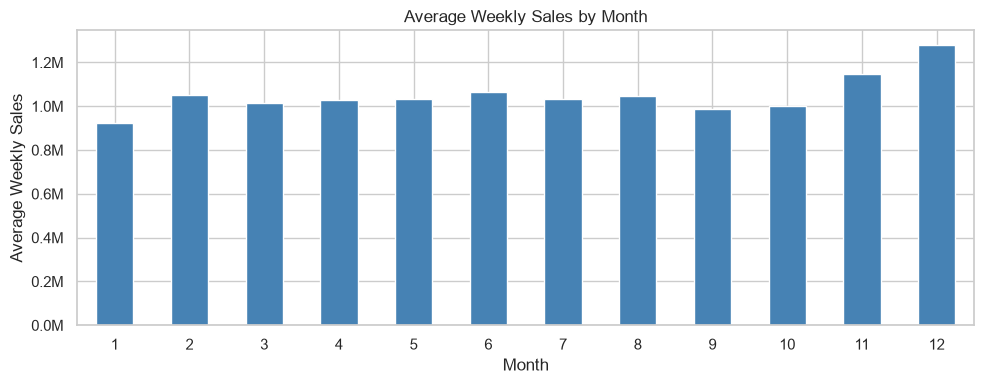

In [20]:
monthly = df.groupby('Month')['Weekly_Sales'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Average Weekly Sales by Month')
ax.set_xlabel('Month')
ax.set_ylabel('Average Weekly Sales')
ax.yaxis.set_major_formatter(millions)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

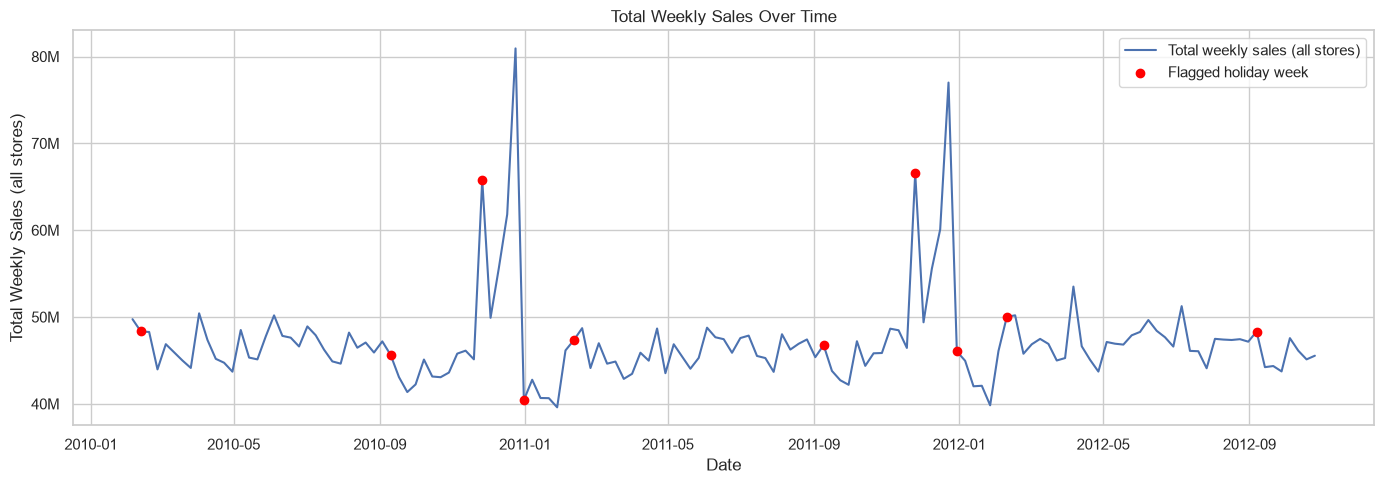

In [21]:
# Total weekly sales over time (all stores)
total = df.groupby('Date')['Weekly_Sales'].sum()
holiday_weeks = pd.DatetimeIndex(df.loc[df['Holiday_Flag'] == 1, 'Date'].unique())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(total.index, total.values, label='Total weekly sales (all stores)')
ax.scatter(holiday_weeks, total.loc[holiday_weeks], color='red', zorder=3, label='Flagged holiday week')
ax.set_title('Total Weekly Sales Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Total Weekly Sales (all stores)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
ax.legend()
plt.tight_layout()
plt.show()

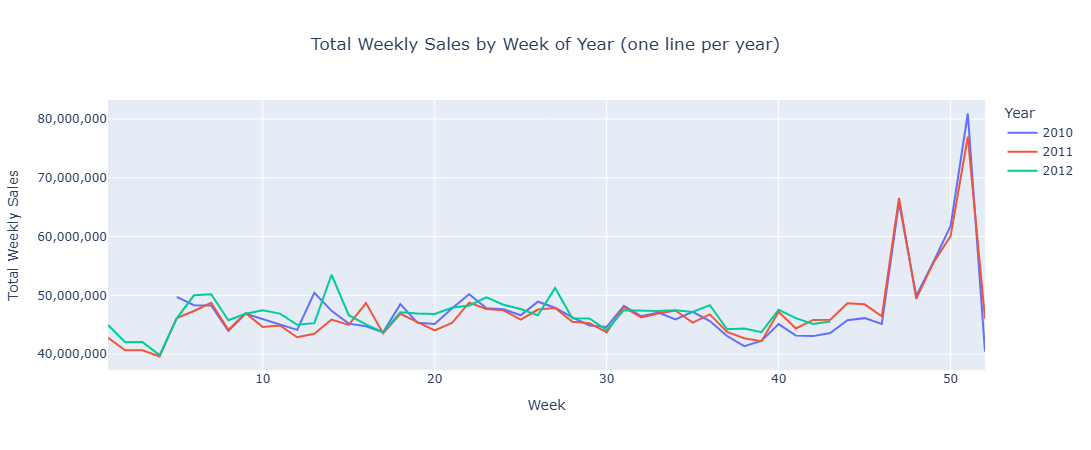

      Avg_total_per_week  Weeks_in_data
Year                                   
2010       47,685,127.51             48
2011       47,080,769.37             52
2012       46,514,717.66             43


In [22]:
total_df = total.reset_index()
total_df.columns = ['Date', 'Total_Sales']
total_df['Year'] = total_df['Date'].dt.year.astype(str)
total_df['Week'] = total_df['Date'].dt.isocalendar().week.astype(int)

fig = px.line(total_df, x='Week', y='Total_Sales', color='Year',
              title='Total Weekly Sales by Week of Year (one line per year)',
              labels={'Total_Sales': 'Total Weekly Sales'})
fig.update_layout(width=1000, height=450, title_x=0.5)
fig.update_yaxes(tickformat=',.0f')
fig.show()

# 2010 and 2012 are partial years, so compare weekly averages instead of yearly totals
print(total_df.groupby('Year')['Total_Sales'].agg(['mean', 'count']).rename(
    columns={'mean': 'Avg_total_per_week', 'count': 'Weeks_in_data'}))

### 3.6. Correlation Between Features

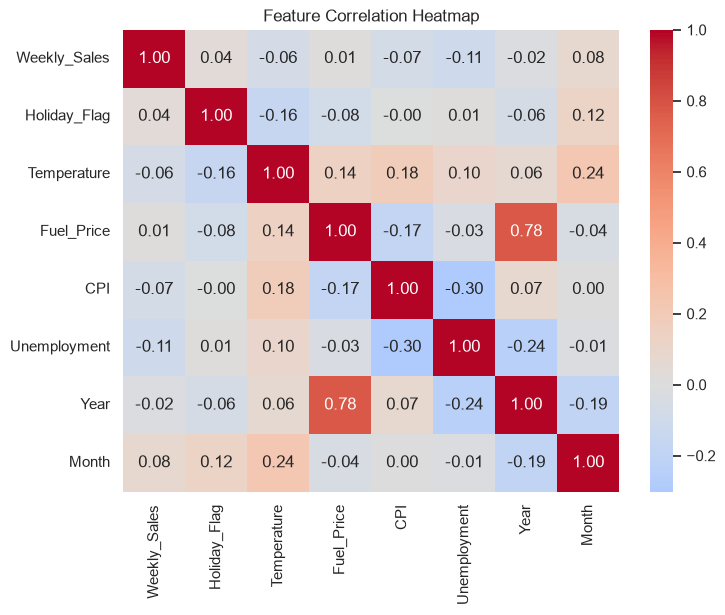

In [23]:
corr_cols = ['Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month']

plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.show()

### 3.7. EDA Summary

**1. Histogram of** `Weekly_Sales` **(raw)**
The distribution is moderately right-skewed (skewness = 0.668). The mean (about 1.05M) is higher than the median (about 0.96M). Multiple peaks suggest a mix of small, medium and large stores.

**2. Boxplot of** `Weekly_Sales`
The middle 50% of weekly sales falls between roughly 0.55M and 1.42M. Outliers appear only on the upper side (about 2.7M to 3.8M) and none on the lower side. These are likely holiday weeks at large stores, so they are kept.

**3. Histogram of** `log1p(Weekly_Sales)`
The log transform makes the distribution more symmetric (skewness = -0.306), but it stays multimodal. The multiple peaks come from differences in store scale, not from skewness. Since the skew is only moderate, a log transform is optional for tree-based models.

**4. Boxplot of** `Weekly_Sales` **by Store**
Median sales differ widely across stores, from about 0.3M to over 2M. Almost every store has upper outliers following the same pattern, so the outliers in the pooled histogram are normal spikes within each store and not anomalies.

**5. Mean and standard deviation by Store**
The smallest store (Store 33) averages about 260K per week, while the largest (Store 20) averages about 2.1M, roughly an 8x gap. The standard deviation grows with store size in absolute terms, but relative to the mean it stays within roughly 5-20% for most stores. Store identity is the main driver of sales.

**6. Outlier check on features**
`Unemployment` has 481 outliers (about 7.5%) from only 6 stores. Unemployment is regional, so these reflect local conditions and are kept. `Temperature` has 3 outliers (extreme but plausible cold weeks), which are also kept. `Fuel_Price` and `CPI` have no outliers.

**7. Holiday vs non-holiday weeks**
Holiday weeks average about 7.84% higher than regular weeks. However, the lift comes almost entirely from Thanksgiving (about +38%). Super Bowl adds only a small increase (about +3%), Labor Day is roughly 0%, and the Christmas week is negative. A single holiday flag hides these differences, so holidays are split into separate features.

**8. Trend and seasonality**
The yearly sales pattern is almost identical across years, with a clear peak in November-December. 2010 starts in February and 2012 ends in October, so total sales per year are not directly comparable; compare the shape of the pattern or the average per week. The average total sales per week declines only slightly (about 1% per year).

**9. Correlation between features**
`Temperature`, `Fuel_Price`, `CPI` and `Unemployment` show only weak linear correlation with `Weekly_Sales`. This does not rule out other types of relationship, and store differences may also hide patterns.

**Overall implications for modeling**
- `Store` must be included as a feature and encoded as a category (it is a label, not a quantity).
- Split holidays into separate features instead of using one `Holiday_Flag`.
- Use `Month` and `Week` to capture seasonality.
- Lag and rolling features should be computed per store.
- Outliers are not removed.
- Split train and test by time, not randomly.
- Use the raw target for tree-based models. Log transform is optional for linear regression.
- Use a per-store average as a baseline before building complex models.

# 4. Feature Engineering

### 4.1. Holiday Type Features

In [24]:
# One combined Holiday_Flag makes the model treat all holidays the same and loses information,
# so the flag is split into one column per holiday (identified by the month of the flagged week)
df['super_bowl']   = ((df['Holiday_Flag'] == 1) & (df['Month'] == 2)).astype(int)
df['labor_day']    = ((df['Holiday_Flag'] == 1) & (df['Month'] == 9)).astype(int)
df['thanksgiving'] = ((df['Holiday_Flag'] == 1) & (df['Month'] == 11)).astype(int)
df['25_december']    = ((df['Holiday_Flag'] == 1) & (df['Month'] == 12)).astype(int)

In [25]:
holiday_type = ['super_bowl', 'labor_day', 'thanksgiving', '25_december']
print(df[holiday_type].sum())
print('Total:', df[holiday_type].sum().sum())
print('Holiday_Flag:', df['Holiday_Flag'].sum())   # should equal the total

super_bowl      135
labor_day       135
thanksgiving     90
25_december      90
dtype: int64
Total: 450
Holiday_Flag: 450


### 4.2. Feature Selection

In [26]:
feature_cols = ['Store','Year','Month','Week','super_bowl','labor_day','thanksgiving','25_december','Temperature','Fuel_Price','CPI','Unemployment']


# 5. Train-Test Split (Time-Based)

### 5.1. Define Features (X) and Target (y)

In [27]:
X = df[feature_cols]
y = df['Weekly_Sales_log']

### 5.2. Split by Time

In [28]:
cutoff = pd.Timestamp('2011-11-01')
train_mask = df['Date'] < cutoff

X_train, X_test = X[train_mask], X[-train_mask]
y_train, y_test = y[train_mask], y[-train_mask]

print(f'Train: {X_train.shape} {df.loc[train_mask, 'Date'].min().date()} to {df.loc[train_mask, 'Date'].max().date()}')
print(f'Test: {X_test.shape} {df.loc[~train_mask, 'Date'].min().date()} to {df.loc[~train_mask, 'Date'].max().date()}')

print(df.loc[-train_mask, holiday_type].sum())

Train: (4095, 12) 2010-02-05 to 2011-10-28
Test: (2340, 12) 2011-11-04 to 2012-10-26
super_bowl      45
labor_day       45
thanksgiving    45
25_december     45
dtype: int64


# 6. Baseline Models

### 6.1. Dummy Regressor (Global Mean)

In [29]:
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print('MAE :', round(mean_absolute_error(y_test, pred_dummy), 3))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_dummy)), 3))
print('R2 :', round(r2_score(y_test, pred_dummy), 3))

MAE : 0.501
RMSE : 0.588
R2 : -0.003


### 6.2. Store-Mean Baseline (from Train Data Only)

In [30]:
#the average by store, calculated only data train
store_mean = y_train.groupby(df.loc[train_mask, 'Store']).mean()
pred_store = df.loc[~train_mask, 'Store'].map(store_mean)

print('MAE :', round(mean_absolute_error(y_test, pred_store), 3))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_store)), 3))
print('R2 :', round(r2_score(y_test, pred_store), 3))

MAE : 0.097
RMSE : 0.141
R2 : 0.942


*The global-mean Dummy model has R² close to 0 (MAE 0.501, RMSE 0.588), as expected for a model that ignores all features. The Store-Mean baseline lowers MAE to 0.097 and reaches R² 0.942, so store identity alone already explains most of the variation. Metrics here are on the log1p scale, and every later model must beat Store-Mean (MAE 0.097, RMSE 0.141, R² 0.942).*

# 7. Preprocessing Pipeline

### 7.1. One-Hot Encoding for `Store` 
### 7.2. Scaling Numerical Features
### 7.3. ColumnTransformer and Pipeline

In [31]:
cat_cols = ['Store']
bin_cols = ['super_bowl', 'labor_day', 'thanksgiving','25_december']
time_cols = ['Year','Month','Week']
num_cols = ['Temperature','Fuel_Price','CPI','Unemployment']

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('bin', 'passthrough', bin_cols),
    ('time', StandardScaler(), time_cols),
    ('num', StandardScaler(), num_cols)
])

*`Store` is one-hot encoded because it is a label, not a quantity. The four holiday columns are already 0/1 and pass through unchanged, while `Year`, `Month`, `Week`, `Temperature`, `Fuel_Price`, `CPI` and `Unemployment` are standardized. Everything sits inside a `Pipeline`, so the encoder and scaler are fitted on training data only (no leakage). Tree models do not need scaling, but it does no harm.*

# 8. Modeling

### 8.1. Ridge Regression

In [32]:
model = Pipeline([
    ('prep', preprocess),
    ('model', Ridge(alpha=1.0))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print('MAE :', round(mean_absolute_error(y_test, pred), 3))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print('R2 :', round(r2_score(y_test, pred), 3))

MAE : 0.149
RMSE : 0.18
R2 : 0.906


### 8.2. Random Forest

In [33]:
rf_model = Pipeline([
    ('prep', preprocess),
    ('model', RandomForestRegressor(n_estimators=250, random_state=42,n_jobs=-1))
])
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

print('MAE :', round(mean_absolute_error(y_test, pred_rf), 3))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_rf)), 3))
print('R2 :', round(r2_score(y_test, pred_rf), 3))

MAE : 0.096
RMSE : 0.134
R2 : 0.948


### 8.3. Extra Tree Regressor

In [34]:
et_model = Pipeline([
    ('prep', preprocess),
    ('model', ExtraTreesRegressor(n_estimators=250, random_state=42,n_jobs=-1))
])

et_model.fit(X_train, y_train)
pred_et = et_model.predict(X_test)

print('MAE :', round(mean_absolute_error(y_test, pred_et), 3))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_et)), 3))
print('R2 :', round(r2_score(y_test, pred_et), 3))

MAE : 0.065
RMSE : 0.091
R2 : 0.976


### 8.4. Hist Gradient Boosting Regressor

In [35]:
preprocess_dense = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['Store']),
    ('bin', 'passthrough', ['super_bowl', 'labor_day', 'thanksgiving','25_december']),
    ('time', StandardScaler(), ['Year','Month','Week']),
    ('num', StandardScaler(), ['Temperature','Fuel_Price','CPI','Unemployment'])
], sparse_threshold=0)

hgb_model = Pipeline([
    ('prep', preprocess_dense),
    ('model', HistGradientBoostingRegressor(max_iter=500, random_state=42, learning_rate=0.05))
])

hgb_model.fit(X_train, y_train)
pred_hgb = hgb_model.predict(X_test)

print('MAE :', round(mean_absolute_error(y_test, pred_hgb), 3))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_hgb)), 3))
print('R2 :', round(r2_score(y_test, pred_hgb), 3))

MAE : 0.092
RMSE : 0.124
R2 : 0.955


*Test-set comparison (log1p scale):*

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Ridge | 0.149 | 0.180 | 0.906 |
| Random Forest | 0.096 | 0.134 | 0.948 |
| Extra Trees | **0.065** | **0.091** | **0.976** |
| HistGradientBoosting | 0.092 | 0.124 | 0.955 |

*Ridge is worse than the Store-Mean baseline, which suggests a linear model cannot use the seasonal and holiday information well. Random Forest and HistGradientBoosting beat the baseline only slightly. Extra Trees is clearly the best and is selected for cross-validation.*

# 9. Cross-Validation (TimeSeriesSplit)

In [36]:
order = df.loc[train_mask, 'Date'].argsort().values
X_tr = X_train.iloc[order]
y_tr = y_train.iloc[order]

tscv = TimeSeriesSplit(n_splits=4)

In [37]:
models = {
    'Ridge': model,
    'Random Forest' : rf_model,
    'ExtraTrees': et_model,
    'HistGB' : hgb_model
}

results = {}
for name, m in models.items():
    cv = cross_validate(
        m, X_tr, y_tr, cv=tscv, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'],  n_jobs=1
    )
    results[name] = {
        'MAE' : -cv['test_neg_mean_absolute_error'].mean(),
        'RMSE' : -cv['test_neg_root_mean_squared_error'].mean(),
        'R2' : cv['test_r2'].mean(),
        'R2_std' : cv['test_r2'].std(),
    }

print(pd.DataFrame(results).T.round(3))

               MAE  RMSE   R2  R2_std
Ridge         0.12  0.16 0.92    0.07
Random Forest 0.10  0.14 0.93    0.05
ExtraTrees    0.09  0.12 0.95    0.05
HistGB        0.20  0.27 0.65    0.48


*Cross-validation on the training data (4 time-ordered folds) confirms the test ranking: Extra Trees is the best model (MAE 0.09, R² 0.95), followed by Random Forest and Ridge. R² std is 0.05 for the tree ensembles, so they are stable across folds. HistGradientBoosting is unstable with default settings (R² 0.65, std 0.48), possibly because the early folds contain very little training data (not verified). It is not selected.*

# 10. Hyperparameter Tuning

In [38]:
param_dist = {
    'model__n_estimators' : [200, 300, 500],
    'model__max_depth' : [None, 10, 20, 30],
    'model__min_samples_leaf' : [1,2,4],
    'model__max_features' : [1.0, 0.7, 0.5],
}

search = RandomizedSearchCV(
    et_model,
    param_distributions = param_dist,
    n_iter=15,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=1
)

search.fit(X_tr, y_tr)

print(f'Best params {search.best_params_}')
print(f'Best CV MAE {round(-search.best_score_, 3)}')

Best params {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': 1.0, 'model__max_depth': None}
Best CV MAE 0.085


*Best settings: `n_estimators=300`, `min_samples_leaf=2`, `max_features=1.0`, `max_depth=None`. CV MAE improves only slightly, from about 0.09 to 0.085, so Extra Trees is not very sensitive to its hyperparameters. The tuned pipeline `best_model` is used for the final evaluation.*

# 11. Final Evaluation on the Test Set

### 11.1. Metrics on the Original Scale (MAE, RMSE, WAPE)

In [41]:
best_model = search.best_estimator_
pred_log = best_model.predict(X_test)

#log scale
print('MAE (log) :', round(mean_absolute_error(y_test, pred_log), 3))
print('R2 (log) :', round(r2_score(y_test,  pred_log), 3))

#scale without log
y_true = np.expm1(y_test)
y_pred = np.expm1(pred_log)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
wape = np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)


print(f'MAE {round(mae, 2)}')
print(f'RMSE {round(rmse, 2)}')
print(f'WAPE {round(wape * 100, 2)} %')

MAE (log) : 0.07
R2 (log) : 0.97
MAE 76919.14
RMSE 143585.57
WAPE 7.2 %


*On the test set the tuned Extra Trees model reaches MAE 0.07 and R² 0.97 on the log scale, in line with the untuned model (MAE 0.065, R² 0.976). On the original scale the MAE is about 76,919 per store per week, RMSE is 143,586 and WAPE is 7.2%. RMSE is about 1.9x MAE, so a few large errors dominate; section 12.1 shows they come from holiday weeks.*

### 11.2. Predicted vs Actual

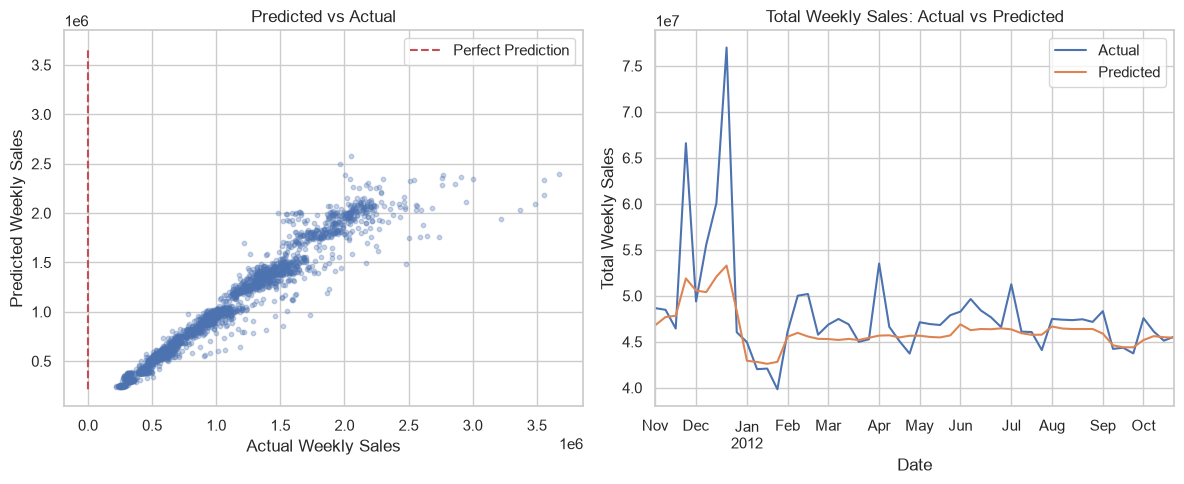

In [42]:
fig, ax = plt.subplots(1,2, figsize=(12,5))

#1.scatter predicted vs actual
ax[0].scatter(y_true, y_pred, alpha=0.3, s=10)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
ax[0].plot(lims, 'r--', label='Perfect Prediction')
ax[0].set_xlabel('Actual Weekly Sales')
ax[0].set_ylabel('Predicted Weekly Sales')
ax[0].set_title('Predicted vs Actual')
ax[0].legend()

#2. Weekly total across al stores
cmp = (pd.DataFrame({
    'Date' : df.loc[-train_mask, 'Date'],
    'Actual' : y_true.values,
    'Predicted' : y_pred}).groupby('Date').sum())
cmp.plot(ax=ax[1])
ax[1].set_title('Total Weekly Sales: Actual vs Predicted')
ax[1].set_xlabel('Date')
ax[1].set_ylabel('Total Weekly Sales')

plt.tight_layout()
plt.show()

*The model tracks baseline weekly sales closely (WAPE 7.2%) but systematically underestimates peak holiday weeks, particularly Thanksgiving 2011 and the late-December peak, likely because the training period contains only one holiday season.*

# 12. Model Interpretation

### 12.1. Residual Analysis

              n_rows        MAE  WAPE_%  Bias_%
Period                                         
25_december       45 107,633.92   10.52   -5.02
labor_day         45  67,794.97    6.31    5.05
non_holiday     2160  70,865.64    6.69    3.33
super_bowl        45  93,661.76    8.43    8.08
thanksgiving      45 329,153.79   22.24   22.08


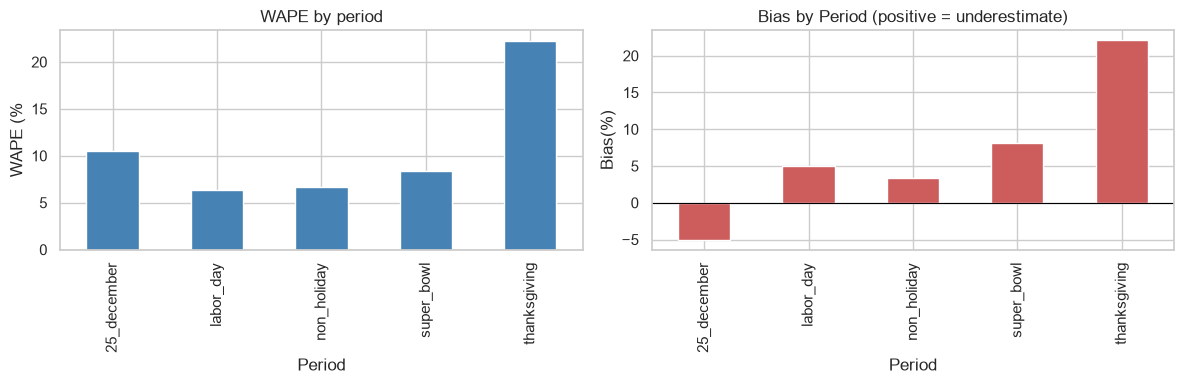

In [51]:
hol_cols = ['super_bowl', 'labor_day', 'thanksgiving', '25_december']

res = pd.DataFrame({
    'Date' : df.loc[-train_mask, 'Date'].values,
    'Store' : X_test['Store'].values,
    'Actual' : y_true.values,
    'Predicted' : y_pred
})

#error> 0 means the model underestimated
res['Error'] = res["Actual"] - res['Predicted']
res['AbsError'] = res['Error'].abs()

#label each row:
res['Period'] = np.select(
    [X_test[c].values == 1 for c in hol_cols],hol_cols, default='non_holiday'

)

#summary per period
summary =res.groupby('Period').agg(
    n_rows=('Error','size'), actual_sum=('Actual', 'sum'), error_sum=('Error','sum'), abs_error_sum=('AbsError', 'sum'), MAE=('AbsError','mean'))
summary['WAPE_%'] = summary['abs_error_sum']/ summary['actual_sum'] * 100
summary['Bias_%'] = summary['error_sum']/ summary['actual_sum'] * 100
print(summary[['n_rows','MAE','WAPE_%','Bias_%']].round(2))

#plot
fig, ax = plt.subplots(1,2, figsize=(12,4))
summary['WAPE_%'].plot.bar(ax=ax[0],color='steelblue')
ax[0].set_title('WAPE by period')
ax[0].set_ylabel('WAPE (%')

summary['Bias_%'].plot.bar(ax=ax[1],color='indianred')
ax[1].axhline(0, color='black', lw=0.8)
ax[1].set_title('Bias by Period (positive = underestimate)')
ax[1].set_ylabel('Bias(%)')

plt.tight_layout()
plt.show()

*Error is concentrated in Thanksgiving week (WAPE 22.2%, bias +22.1%), where the model systematically underestimates sales. Other holiday weeks and non-holiday weeks have WAPE between 6.3% and 10.5%.*

### 12.2. Feature Importance

Store          95.95
CPI             1.32
Week            0.72
Month           0.56
Temperature     0.37
Unemployment    0.33
Fuel_Price      0.29
Year            0.24
thanksgiving    0.10
25_december     0.08
labor_day       0.02
super_bowl      0.01
dtype: float64


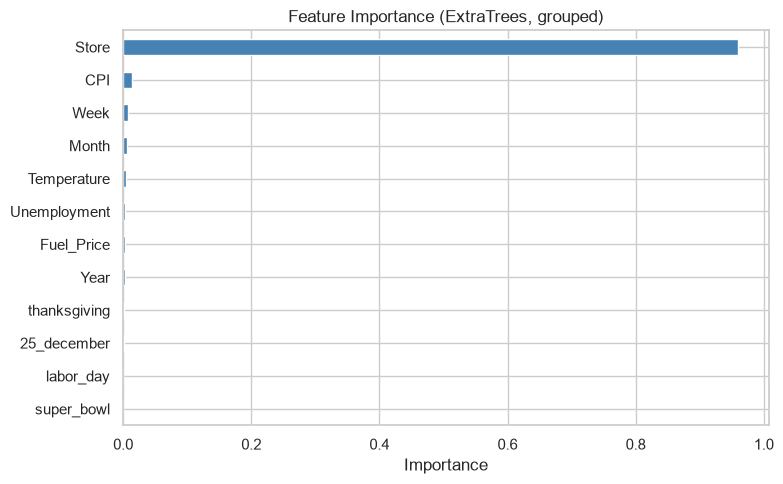

In [53]:
# get the fitted steps from the tuned pipeline
prep = best_model.named_steps['prep']
et = best_model.named_steps['model']

#feature names after preprocessing 
feat_names = prep.get_feature_names_out()
imp = pd.Series(et.feature_importances_, index=feat_names)

#group the one hot store column back into asingle feat
def base_name(n):
    n = n.split('__',1)[1]
    return 'Store' if n.startswith('Store_') else n

imp_grouped = imp.groupby(base_name).sum().sort_values(ascending=False)
print((imp_grouped * 100).round(2))

#plot
fig, ax = plt.subplots(figsize=(8,5))
imp_grouped.sort_values().plot.barh(ax=ax, color='steelblue')
ax.set_title('Feature Importance (ExtraTrees, grouped)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

*Store identity accounts for about 96% of the model's feature importance, indicating that weekly sales are driven mainly by store level differences. Holiday flags, seasonal variables and economic indicators contribute little in impurity-based importance, although holiday weeks show the largest prediction errors (Thanksgiving WAPE 22.2%)*

In [57]:
r = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_absolute_error', n_jobs=1)
perm = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(perm.round(4))

Store          0.59
CPI            0.05
Month          0.01
Week           0.01
Unemployment   0.00
thanksgiving   0.00
Temperature    0.00
25_december    0.00
Fuel_Price     0.00
labor_day      0.00
super_bowl     0.00
Year           0.00
dtype: float64


*Permutation importance on the test set confirms that Store is by far the most influential feature (MAE increase of 0.59 on the log scale), followed by CPI (0.05). Holiday flags show near-zero average importance because each holiday covers only one week (45 rows) of the 2,340 test rows, even though holiday weeks, especially Thanksgiving, show the largest errors.*

# 13. Conclusion and Recommendations

### 13.1. Conclusion

**Final result.** The tuned Extra Trees model predicts weekly sales per store on a time-based test set (Nov 2011 to Oct 2012, 2,340 rows, 45 stores) with **WAPE 7.2%**, **MAE about 76,919** and **RMSE about 143,586** per store per week on the original scale. On the log1p scale the test MAE is 0.07 and R² is 0.97.

**Model comparison (test set, log1p scale).**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Dummy (global mean) | 0.501 | 0.588 | -0.003 |
| Store-Mean baseline | 0.097 | 0.141 | 0.942 |
| Ridge | 0.149 | 0.180 | 0.906 |
| Random Forest | 0.096 | 0.134 | 0.948 |
| HistGradientBoosting | 0.092 | 0.124 | 0.955 |
| **Extra Trees (before tuning)** | **0.065** | **0.091** | **0.976** |

**Key findings**
1. **Store identity is the main driver of sales.** Store 20 averages about 2.1M per week and Store 33 about 0.26M (about 8x). The Store-Mean baseline alone reaches R² 0.942, Store holds about 96% of the impurity-based importance, and shuffling Store raises MAE by 0.59 (log scale) in the permutation test.
2. **Extra Trees adds a real but moderate gain over the baseline.** Test MAE falls from 0.097 to 0.065 (about 33%). Ridge did not beat the baseline, and Random Forest only matched it, so the gain comes from non-linear patterns that a linear model cannot capture.
3. **The ranking is stable.** Time-series cross-validation (4 folds) gives the same order (Extra Trees best, CV MAE about 0.09, R² 0.95). Tuning improved CV MAE only slightly (to 0.085), so the model is not very sensitive to its hyperparameters. HistGradientBoosting was unstable in CV (R² 0.65, std 0.48) with default settings.
4. **Errors are concentrated in holiday weeks.** Thanksgiving week has WAPE 22.2% and bias +22.1% (systematic underestimation, MAE about 329K, 4.6x the non-holiday MAE). Non-holiday weeks have WAPE 6.7%. Other holiday weeks are between 6.3% and 10.5%. This explains why RMSE is about 1.9x MAE.
5. **Thanksgiving is the only holiday with a large sales lift** (about +38% versus a store's average week in the EDA). Super Bowl is about +3%, Labor Day about 0%, and the flagged Christmas week is about -8%.

### 13.2. Recommendations

1. **Use the tuned Extra Trees model for routine weekly planning.** In normal weeks the error is about 7% of sales, which is a useful level for store-level forecasts.
2. **Handle Thanksgiving week separately.** Because the model underestimates it by about 22%, add a manual uplift or a holiday-specific correction (for example, a per-store Thanksgiving ratio from past years) before using the forecast for stock or staffing.
3. **Add features that describe time more precisely.** Lag and rolling-average sales per store, days to the next holiday, and a flag for the week before Christmas. The weekly plot in section 11.2 suggests the late-December peak is not covered by the flagged Christmas week (not verified yet).
4. **Collect more history.** With about 2.7 years, each holiday appears only once or twice in training. Three to five years would let the model learn holiday effects properly.
5. **Retrain regularly with an expanding window** and monitor WAPE and bias separately for holiday and non-holiday weeks.
6. **Report WAPE together with bias.** WAPE is easy to explain to business users, and bias shows whether the model systematically over- or underestimates.
7. **Add store attributes** (size, region, store type) and promotion data if available. They are not in this dataset, and store differences currently explain most of the variation without a known reason.

### 13.3. Limitations

- **Short history and few holiday events.** Each holiday covers one week in the test set (45 rows), so holiday results are an indication, not strong statistical evidence. The training period contains only one Thanksgiving and one Christmas season.
- **Test set was viewed during model comparison.** Ridge, Random Forest, Extra Trees and HistGradientBoosting were compared on the test set before cross-validation. This can make the test score slightly optimistic. The cross-validation ranking points to the same model, which supports the choice.
- **Economic and weather variables are treated as known.** In real forecasting, `Temperature`, `Fuel_Price`, `CPI` and `Unemployment` of future weeks are not known and would need their own forecasts. The model also has no lag features, so it is not a true multi-step forecaster.
- **The model is mostly a store-level lookup with small adjustments.** Feature importance is not causal. `CPI` ranks second but may be acting as a proxy for time or store.
- **Holiday labels are inferred.** The four holiday columns are derived from `Holiday_Flag` and the month of the flagged week. The week before Christmas is not flagged and is therefore counted as non-holiday.
- **Target transformation.** The model is trained on `log1p(Weekly_Sales)` and converted back with `expm1`. This back-transformation can bias predictions slightly downward, and a model on the raw target was not compared.
- **Limited tuning.** Only Extra Trees was tuned (15 random combinations, 4 time folds). HistGradientBoosting was not tuned and its unstable CV result was not investigated. The cross-validation folds are cut by row order, so a boundary can fall inside one week.
- **No prediction intervals.** The model gives point forecasts only, with no measure of uncertainty.

### 13.4. References

- Kaggle, *Walmart Dataset (Retail)*: https://www.kaggle.com/datasets/rutuspatel/walmart-dataset-retail
- Kaggle competition, *Walmart Recruiting: Store Sales Forecasting*: https://www.kaggle.com/c/walmart-recruiting-store-sales-forecasting
- Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Geurts, Ernst and Wehenkel (2006). Extremely randomized trees. *Machine Learning*, 63(1), 3-42.
- Breiman (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
- scikit-learn documentation: https://scikit-learn.org/stable/
- pandas documentation: https://pandas.pydata.org/docs/